In [1]:
# Packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("bmh")

### 1. Wykonaj analizę struktury z podziałem na cechy ciągłe i skokowe oraz graficzną oceną wyników badania. W ocenie uwzględnij zakres oraz rozkład braków danych.

In [2]:
# Ścieżka do zbioru danych kb06.csv
data_path='kb06.csv'
#Import danych z csv
df=pd.read_csv(data_path)

In [3]:
# Kształt zbioru danych
print('Liczba obserwacji: ' + str(df.shape[0]))
print('Liczba zmiennych: ' + str(df.shape[1]))

Liczba obserwacji: 11304
Liczba zmiennych: 6


In [4]:
# Kilka pierwszych obserwacji
df.head()

,age,education,house_loan,poutcome,contact,y_newdeposit
0,41,secondary,yes,unknown,0,0.0
1,53,secondary,yes,unknown,0,NaN
2,58,unknown,yes,unknown,0,0.0
3,57,secondary,yes,unknown,0,0.0
4,57,primary,yes,unknown,0,0.0


In [5]:
# Rodzaje zmiennych
print("Rodzaje zmiennych:")
df.dtypes

Rodzaje zmiennych:


age               int64
education        object
house_loan       object
poutcome         object
contact           int64
y_newdeposit    float64
dtype: object

In [6]:
# Podział zmiennych na ciągłe i skokowe
cont_var = ['age']
print("Zmienne ciągłe:")
print(cont_var)

disc_var = [
    'education',
    'house_loan',
    'poutcome',
    'contact',
    'y_newdeposit'
]
print("Zmienne skokowe:")
print(disc_var)

Zmienne ciągłe:
['age']
Zmienne skokowe:
['education', 'house_loan', 'poutcome', 'contact', 'y_newdeposit']


In [7]:
# Statystyki zmiennej ciągłej
df[cont_var].describe().round(2)

,age
count,11304.00
mean,41.00
std,10.67
min,18.00
25%,33.00
50%,39.00
75%,49.00
max,92.00


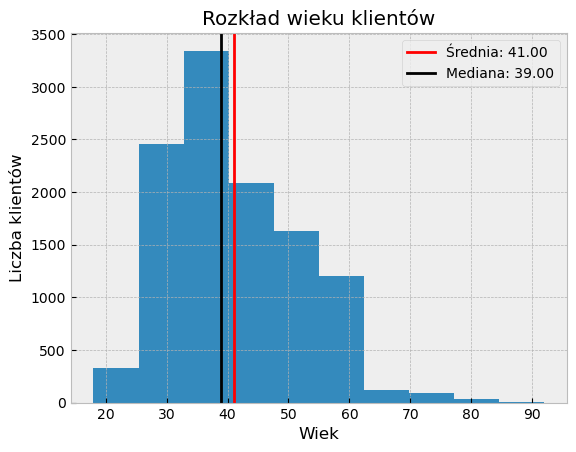

In [8]:
# Rozkład wieku klientów
plt.hist(df['age'])
plt.axvline(df['age'].mean(), color='red', 
           label=f"Średnia: {df['age'].mean():.2f}")
plt.axvline(df['age'].median(), color='black',
            label=f"Mediana: {df['age'].median():.2f}")
plt.title('Rozkład wieku klientów')
plt.xlabel('Wiek')
plt.ylabel('Liczba klientów')
plt.legend()
plt.show()

In [9]:
# Statystyki dla zmiennych skokowych
for var in disc_var:
    print(f'\nZmienna: {var}')

    print(pd.DataFrame({
        'Liczebność': df[var].value_counts(dropna=False),
        'Udział (%)': df[var].value_counts(normalize=True, dropna=False) * 100
    }).round(2))


Zmienna: education
           Liczebność  Udział (%)
education                        
secondary        5788       51.20
tertiary         3337       29.52
primary          1712       15.15
unknown           467        4.13

Zmienna: house_loan
            Liczebność  Udział (%)
house_loan                        
yes               6340       56.09
no                4964       43.91

Zmienna: poutcome
          Liczebność  Udział (%)
poutcome                        
unknown         9189       81.29
failure         1263       11.17
other            482        4.26
success          370        3.27

Zmienna: contact
         Liczebność  Udział (%)
contact                        
1              7369       65.19
0              3198       28.29
2               737        6.52

Zmienna: y_newdeposit
              Liczebność  Udział (%)
y_newdeposit                        
0.0                 9332       82.55
NaN                 1418       12.54
1.0                  554        4.90


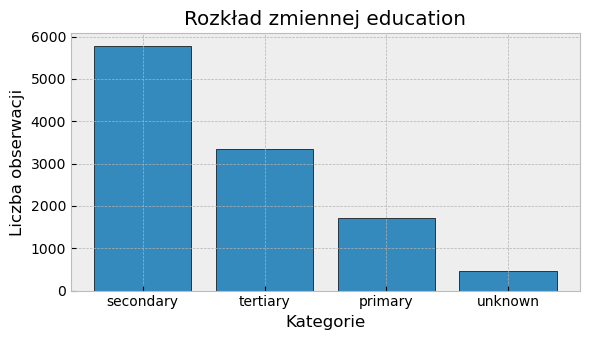

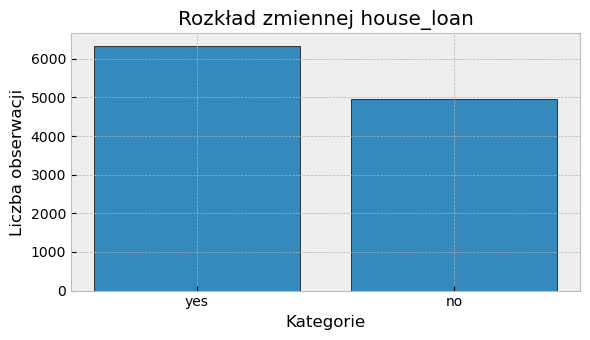

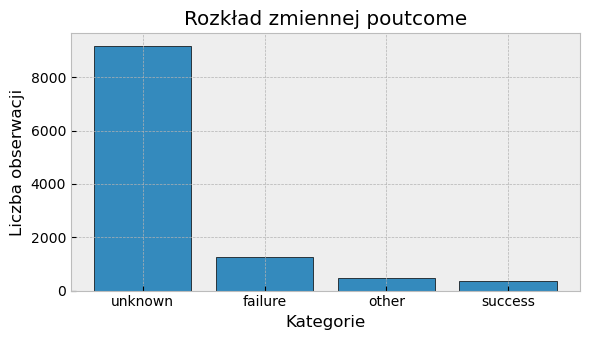

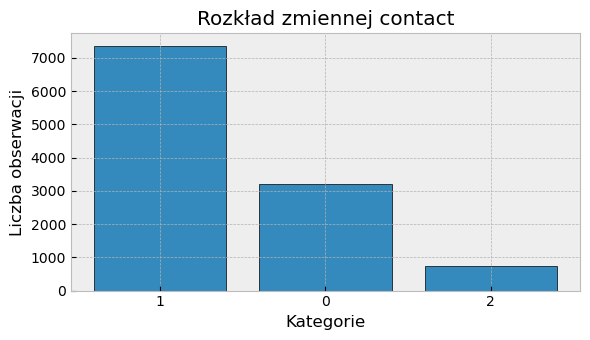

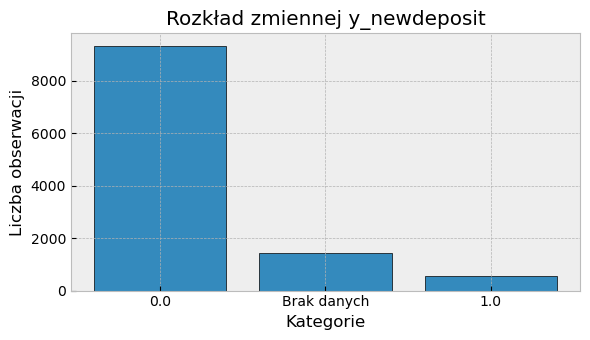

In [10]:
# Wykresy zmiennych skokowych
for var in disc_var:
    counts = df[var].fillna('Brak danych').value_counts()

    plt.figure(figsize=(6, 3.5))
    plt.bar(counts.index.astype(str), counts.values, edgecolor='black')

    plt.title(f'Rozkład zmiennej {var}')
    plt.xlabel('Kategorie')
    plt.ylabel('Liczba obserwacji')

    plt.tight_layout()
    plt.show()

In [11]:
# Braki danych
missing_val = df.isna().sum()
print(missing_val)

age                0
education          0
house_loan         0
poutcome           0
contact            0
y_newdeposit    1418
dtype: int64


In [12]:
# Analiza braków dla y_newdeposit
target_summary  = pd.DataFrame({
    'Liczebność': df['y_newdeposit'].value_counts(dropna=False),
    'Udział (%)': df['y_newdeposit'].value_counts(dropna=False, normalize=True) * 100
})

target_summary.index = target_summary.index.map({
    0: 'Brak zakupu (0)',
    1: 'Zakup (1)'
}).fillna('Brak danych')

print(target_summary)

                 Liczebność  Udział (%)
y_newdeposit                           
Brak zakupu (0)        9332   82.554848
Brak danych            1418   12.544232
Zakup (1)               554    4.900920


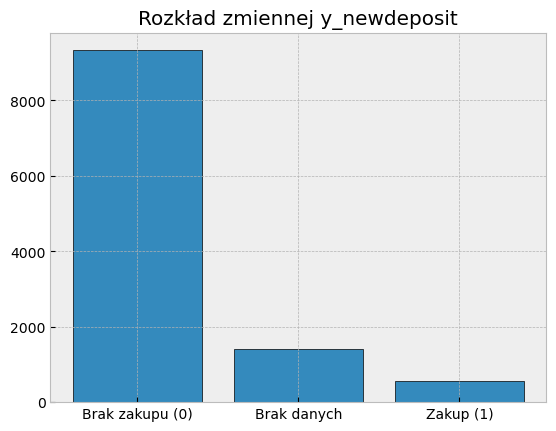

In [18]:
#Wykres zmiennej y_newdeposit
plt.bar(target_summary.index, target_summary.iloc[:, 0], edgecolor='black')
plt.title("Rozkład zmiennej y_newdeposit")
plt.show()

In [14]:
# Wyniki kampanii marketingowej
# Kopia danych do analizy graficznej
df_plot = df.copy()

# Czytelne etykiety
df_plot['y_newdeposit'] = df_plot['y_newdeposit'].map({
    0: 'Brak zakupu',
    1: 'Zakup'
}).fillna('Brak danych')

# Liczebność poszczególnych wyników w grupach komunikacji
tabela_liczebnosci = pd.crosstab(
    df_plot['contact'],
    df_plot['y_newdeposit']
)

tabela_liczebnosci = tabela_liczebnosci[
    ['Zakup', 'Brak zakupu', 'Brak danych']
]

print(tabela_liczebnosci)

y_newdeposit  Zakup  Brak zakupu  Brak danych
contact                                      
0               113         2624          461
1               383         6271          715
2                58          437          242


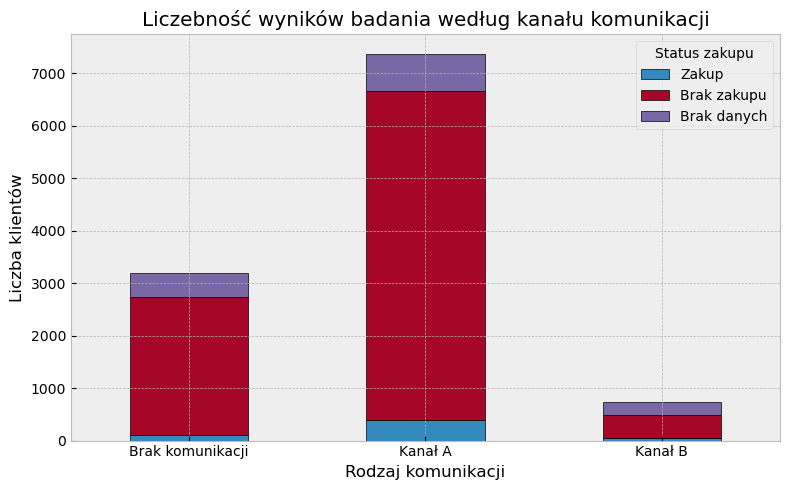

In [15]:
# Wykres liczebności wyników badania
tabela_liczebnosci.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Liczebność wyników badania według kanału komunikacji')
plt.xlabel('Rodzaj komunikacji')
plt.ylabel('Liczba klientów')
plt.xticks(
    ticks=[0, 1, 2],
    labels=['Brak komunikacji', 'Kanał A', 'Kanał B'],
    rotation=0
)
plt.legend(title='Status zakupu')
plt.tight_layout()
plt.show()

In [16]:
# Tabela udziałów procentowych w grupach komunikacji
tabela_wynikow = pd.crosstab(
    df_plot['contact'],
    df_plot['y_newdeposit'],
    normalize='index'
) * 100

# Uporządkowanie kategorii
tabela_wynikow = tabela_wynikow[
    ['Zakup', 'Brak zakupu', 'Brak danych']
]
print(tabela_wynikow)

y_newdeposit     Zakup  Brak zakupu  Brak danych
contact                                         
0             3.533458    82.051282    14.415260
1             5.197449    85.099742     9.702809
2             7.869742    59.294437    32.835821


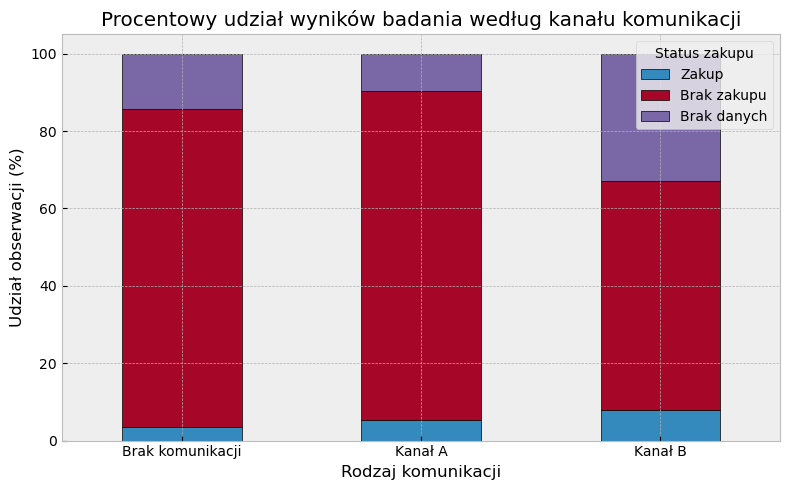

In [17]:
# Wykres skumulowany
tabela_wynikow.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Procentowy udział wyników badania według kanału komunikacji')
plt.xlabel('Rodzaj komunikacji')
plt.ylabel('Udział obserwacji (%)')
plt.xticks(
    ticks=[0, 1, 2],
    labels=['Brak komunikacji', 'Kanał A', 'Kanał B'],
    rotation=0
)
plt.legend(title='Status zakupu')
plt.tight_layout()
plt.show()

### 2. Oceń zależność pomiędzy prawdopodobieństwem braku danych a pozostałymi cechami, aby wskazać czy istnieją takie cechy, za pomocą których możemy dokonać korekty oszacowań stosując imputację danych.